# Surface Tension of Liquid Alloys: Butler Equation

The Butler equation predicts the surface tension of a liquid alloy from the surface tensions of the pure liquids and the excess Gibbs energy of the bulk liquid. Treating the surface as a monolayer in equilibrium with the bulk gives, for each component $i$ of an $n$-component liquid,

$$\sigma = \sigma_i + \frac{RT}{A_i} \ln\frac{x_i^S}{x_i^B} + \frac{1}{A_i}\left[\beta \, G_i^{E}(T, x^S) - G_i^{E}(T, x^B)\right]$$

where $x^B$ and $x^S$ are the bulk and surface compositions, $G_i^E$ is the partial excess Gibbs energy of $i$ in the bulk liquid, $\sigma_i$ is the surface tension of pure liquid $i$ and $A_i = L N_A^{1/3} V_i^{2/3}$ is its molar surface area. The excess Gibbs energy of the surface is $\beta = 0.83$ times that of the bulk at the same composition, and $L = 1.091$ for liquid metals [1]. These $n$ equations and $\sum_i x_i^S = 1$ are solved for $\sigma$ and $x^S$, with $G_i^E$ from the COST 507 light alloys database [2].

In [1]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
from scipy.constants import N_A
from scipy.optimize import root
from pycalphad import Database, Workspace, variables as v

R = float(v.R)  # the gas constant used by the database models

# COST 507 emits benign warnings at load about unused type-definition characters
warnings.filterwarnings('ignore', category=UserWarning, module='pycalphad.io.tdb')

## Pure element data

The pure liquids follow $\sigma_i(T) = \sigma_{m,i} + \frac{d\sigma_i}{dT}(T - T_{m,i})$ and $V_i(T) = V_{m,i}\left[1 + \alpha_i (T - T_{m,i})\right]$. Surface tensions are from [3] for Al and Cu, [4] for Si and [5] for Cr, Nb and Ti. Molar volumes and expansion coefficients are from [6].

In [2]:
#        sigma_m [N/m], dsigma/dT [N/m/K], T_m [K], V_m [m^3/mol], alpha [1/K]
PURE = {
    'AL': (0.871, -1.55e-4,  933, 11.3e-6, 1.5e-4),
    'CR': (1.780, -5.44e-4, 2148, 8.27e-6, 1.1e-4),
    'CU': (1.300, -2.64e-4, 1358, 7.94e-6, 1.0e-4),
    'NB': (1.937, -1.99e-4, 2742, 11.9e-6, 0.51e-4),
    'SI': (0.850, -2.50e-4, 1683, 11.1e-6, 1.4e-4),
    'TI': (1.560, -1.65e-4, 1941, 11.6e-6, 0.56e-4),
}

## Butler surface tension as a computable property

We implement a self-contained `ButlerSurfaceTension` class that follows PyCalphad's `ComputableProperty` protocol and solves the Butler equations. It returns NaN unless the liquid is the only stable phase.

In [3]:
class ButlerSurfaceTension:
    implementation_units = 'N/m'
    display_units = 'mN/m'
    display_name = 'Surface tension'
    shape = ()

    def __init__(self, pure_data, phase='LIQUID', beta=0.83, L=1.091):
        self.pure_data = pure_data
        self.phase = phase
        self.beta = beta
        self.L = L

    def __str__(self):
        return f'SIGMA({self.phase})'

    def excess_chemical_potentials(self, compset, x):
        "mu_i - RT ln(x_i) at mole fractions x, from the tangent to the molar Gibbs energy of the phase"
        # assumes a single sublattice with ideal configurational entropy, so site fractions are mole fractions
        phase_record = compset.phase_record
        dof = np.append(compset.dof[:phase_record.num_statevars], x)
        GM, grad = np.zeros(1), np.zeros(dof.size)
        phase_record.prop(GM, dof, b'GM')
        phase_record.prop_grad(grad, dof, b'GM')
        dGM_dx = grad[phase_record.num_statevars:]
        T = dof[phase_record.state_variables.index(v.T)]
        return GM + dGM_dx - x @ dGM_dx - R * T * np.log(x)

    def solve(self, compset):
        "Return the surface tension (N/m) and surface composition of a liquid composition set"
        phase_record = compset.phase_record
        T = compset.dof[phase_record.state_variables.index(v.T)]
        x_bulk = np.array(compset.X)
        sigma_m, dsigma_dT, T_m, V_m, alpha = np.array([self.pure_data[el] for el in phase_record.nonvacant_elements]).T
        sigma_pure = sigma_m + dsigma_dT * (T - T_m)
        A = self.L * N_A**(1/3) * (V_m * (1 + alpha * (T - T_m)))**(2/3)
        G_pure = np.diag([self.excess_chemical_potentials(compset, x) for x in np.eye(x_bulk.size)])
        G_excess = lambda x: self.excess_chemical_potentials(compset, x) - G_pure
        G_bulk = G_excess(x_bulk)

        def residuals(z):  # z = [ln(x_surface), sigma]
            ln_x_surface, sigma = z[:-1], z[-1]
            G_surface = self.beta * G_excess(np.exp(ln_x_surface))
            butler = ln_x_surface - np.log(x_bulk) + (G_surface - G_bulk - A * (sigma - sigma_pure)) / (R * T)
            return np.append(butler, np.exp(ln_x_surface).sum() - 1)

        sol = root(residuals, np.append(np.log(x_bulk), x_bulk @ sigma_pure))
        if not sol.success:
            return np.nan, np.full_like(x_bulk, np.nan)
        return sol.x[-1], np.exp(sol.x[:-1])

    def compute_property(self, compsets, cur_conds, chemical_potentials):
        if len(compsets) == 1 and compsets[0].phase_record.phase_name == self.phase:
            return self.solve(compsets[0])[0]
        return np.nan

sigma = ButlerSurfaceTension(PURE)

## Binary: Al-Cu

At 1373 K, Al-Cu is liquid at all compositions. Schmitz et al. [3] measured its surface tension by electromagnetic levitation (Table 2) and used the same COST 507 liquid in a Butler model with $\beta = 0.66$, which is also shown.

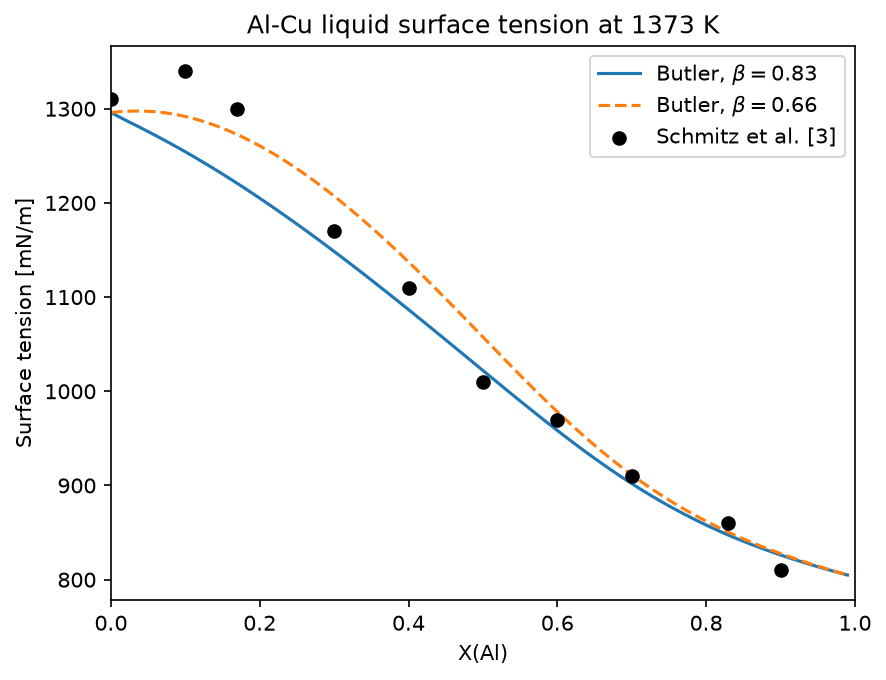

In [4]:
dbf = Database('../databases/COST507.tdb')

exp_x_al = [0.0, 0.10, 0.17, 0.30, 0.40, 0.50, 0.60, 0.70, 0.83, 0.90]
exp_sigma = [1310, 1340, 1300, 1170, 1110, 1010, 970, 910, 860, 810]  # mN/m

conditions = {v.X('AL'): (0, 1, 0.01), v.T: 1373, v.P: 101325, v.N: 1}
wks = Workspace(dbf, ['AL', 'CU', 'VA'], list(dbf.phases.keys()), conditions)
x_al, sigma_083, sigma_066 = wks.get(v.X('AL'), sigma, ButlerSurfaceTension(PURE, beta=0.66))

fig, ax = plt.subplots(dpi=150)
ax.plot(x_al, sigma_083, label=r'Butler, $\beta = 0.83$')
ax.plot(x_al, sigma_066, '--', label=r'Butler, $\beta = 0.66$')
ax.scatter(exp_x_al, exp_sigma, color='k', zorder=3, label='Schmitz et al. [3]')
ax.set_title('Al-Cu liquid surface tension at 1373 K')
ax.set_xlabel('X(Al)')
ax.set_ylabel(f'{sigma.display_name} [{sigma.display_units}]')
ax.set_xlim(0, 1)
_ = ax.legend()

With $\beta = 0.83$, the calculation is within about 2% of the measurements for X(Al) $\geq$ 0.3 but up to 6% low on the Cu-rich side, where $\beta = 0.66$ is closer (within 4%) at the expense of intermediate compositions. $\beta = 0.83$ is used below.

## Ternary: Al-Cu-Si

The surface tension at 1373 K is plotted where the liquid is the only stable phase.

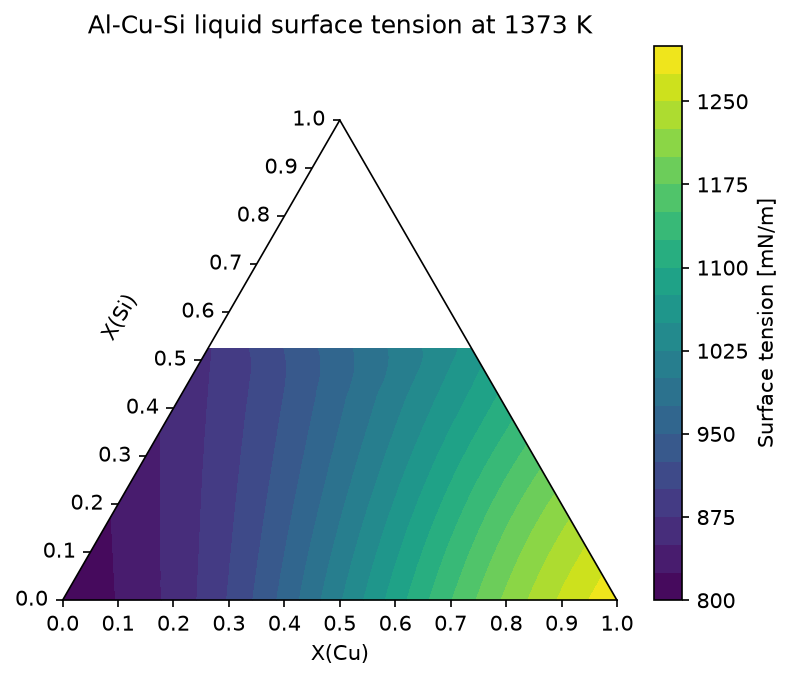

In [5]:
conditions = {v.X('CU'): np.linspace(0, 1, 41), v.X('SI'): np.linspace(0, 1, 41), v.T: 1373, v.P: 101325, v.N: 1}
wks = Workspace(dbf, ['AL', 'CU', 'SI', 'VA'], list(dbf.phases.keys()), conditions)
x_cu, x_si, sigma_values = (arr.ravel() for arr in wks.get(v.X('CU'), v.X('SI'), sigma))
liquid = ~np.isnan(sigma_values)

fig = plt.figure(dpi=150)
ax = fig.add_subplot(projection='triangular')
contours = ax.tricontourf(x_cu[liquid], x_si[liquid], sigma_values[liquid], levels=20)
ax.set_title('Al-Cu-Si liquid surface tension at 1373 K')
ax.set_xlabel('X(Cu)')
ax.set_ylabel('X(Si)')
ax.yaxis.label.set_rotation(60)
ax.yaxis.set_label_coords(x=0.12, y=0.5)
_ = fig.colorbar(contours, ax=ax, label=f'{sigma.display_name} [{sigma.display_units}]')

## Multicomponent: Ti-48Al-2Cr-2Nb

The surface tension of the $\gamma$-TiAl alloy Ti-48Al-2Cr-2Nb (atomic %) has been measured by the oscillating drop method in electromagnetic levitation on parabolic flights and on the International Space Station (ISS) [5, 7]. The calculation is compared with the measurements at 1973 K, about 200 K above the liquidus, and the surface composition is taken from `solve`.

In [6]:
# mN/m at 1973 K, compiled in [5]
measured = {'parabolic flight': 1124, 'ISS': 1189, 'ISS [7]': 1235}

conditions = {v.X('AL'): 0.48, v.X('CR'): 0.02, v.X('NB'): 0.02, v.T: 1973, v.P: 101325, v.N: 1}
wks = Workspace(dbf, ['AL', 'CR', 'NB', 'TI', 'VA'], list(dbf.phases.keys()), conditions)

print(f"{sigma.display_name}: {wks.get(sigma):.0f} {sigma.display_units}")
for source, value in measured.items():
    print(f"Measured ({source}): {value} {sigma.display_units}")

liquid, = wks.get_composition_sets()
_, x_surface = sigma.solve(liquid)
for el, x_b, x_s in zip(liquid.phase_record.nonvacant_elements, liquid.X, x_surface):
    print(f'X({el}): bulk {x_b:.4f}, surface {x_s:.4f}')

Surface tension: 1038 mN/m
Measured (parabolic flight): 1124 mN/m
Measured (ISS): 1189 mN/m
Measured (ISS [7]): 1235 mN/m
X(AL): bulk 0.4800, surface 0.7981
X(CR): bulk 0.0200, surface 0.0082
X(NB): bulk 0.0200, surface 0.0018
X(TI): bulk 0.4800, surface 0.1918


The surface is enriched in Al, and the calculated surface tension is 7-16% below the measurements. Novakovic et al. [5] obtained about 1000 mN/m from compound formation and Butler models of the Ti-Al-Cr and Ti-Al-Nb subsystems and regard that as a lower bound for this alloy.

## References

1. [T. Tanaka, K. Hack, T. Iida, S. Hara, *Application of Thermodynamic Databases to the Evaluation of Surface Tensions of Molten Alloys, Salt Mixtures and Oxide Mixtures*, Z. Metallkd. 87 (1996) 380-389](https://doi.org/10.1515/ijmr-1996-870509).
2. [I. Ansara, A.T. Dinsdale, M.H. Rand (Eds.), *COST 507: Thermochemical Database for Light Metal Alloys*, Vol. 2, EUR 18499 EN, Luxembourg (1998)](https://www.opencalphad.com/databases/CGNA18499ENC_001.pdf).
3. [J. Schmitz, J. Brillo, I. Egry, R. Schmid-Fetzer, *Surface tension of liquid Al–Cu binary alloys*, Int. J. Mater. Res. 100 (2009) 1529-1535](https://doi.org/10.3139/146.110221).
4. [K.C. Mills, Y.C. Su, *Review of surface tension data for metallic elements and alloys: Part 1 – Pure metals*, Int. Mater. Rev. 51 (2006) 329-351](https://doi.org/10.1179/174328006X102510).
5. [R. Novakovic, D. Giuranno, M. Mohr, H.-J. Fecht, *Thermodynamic Evaluation of the Surface Tension and Viscosity of Liquid Quaternary Alloys: The Ti-Al-Cr-Nb System*, Microgravity Sci. Technol. 35 (2023) 55](https://doi.org/10.1007/s12217-023-10080-x).
6. T. Iida, R.I.L. Guthrie, *The Physical Properties of Liquid Metals*, Clarendon Press, Oxford (1988).
7. [R.K. Wunderlich et al., *Thermophysical properties of the TiAl-2Cr-2Nb alloy in the liquid phase measured with an electromagnetic levitation device on board the International Space Station, ISS-EML*, Int. J. Mater. Res. 112 (2021) 770-781](https://doi.org/10.1515/ijmr-2021-8266).